In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/project/data.csv')

print(df.head())
print(df.shape)

df = df.dropna(subset=['review', 'sentiment']).copy()

df['review'] = df['review'].astype(str)
df['sentiment'] = df['sentiment'].str.lower().str.strip()

X = df['review']
y = df['sentiment']

encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Sentiment Categories:", encoder.classes_)
print("Number of Classes:", len(encoder.classes_))

                                              review             model  \
0  The movie was a complete snoozefest.  I regret...  Gemini-1.5-Flash   
1  Seriously, the worst venue I've ever been to. ...  Gemini-1.5-Flash   
2  This event was so poorly organized, it was a j...  Gemini-1.5-Flash   
3  What a disaster of a movie!  The acting was aw...  Gemini-1.5-Flash   
4  I wouldn't recommend this venue to my worst en...  Gemini-1.5-Flash   

  sentiment  
0  negative  
1  negative  
2  negative  
3  negative  
4  negative  
(10147, 3)
Sentiment Categories: ['negative' 'neutral' 'positive']
Number of Classes: 3


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
tfidf = TfidfVectorizer(max_features=10000)

A = tfidf.fit_transform(x_train)
B = tfidf.transform(x_test)

print("Training Shape:", A.shape)
print("Testing Shape:", B.shape)

Training Shape: (8116, 6489)
Testing Shape: (2029, 6489)


In [ ]:
fnn = Sequential([
    Input(shape=(A.shape[1],)),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(64, activation='relu'),

    Dense(len(encoder.classes_), activation='softmax')
])

fnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

fnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       830,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 839,171 (3.20 MB)

 Trainable params: 839,171 (3.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = fnn.fit(
    A.toarray(),
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.7254 - loss: 0.7124 - val_accuracy: 0.8966 - val_loss: 0.2984
Epoch 2/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9518 - loss: 0.1540 - val_accuracy: 0.9150 - val_loss: 0.2347
Epoch 3/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9904 - loss: 0.0475 - val_accuracy: 0.9107 - val_loss: 0.2474
Epoch 4/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9963 - loss: 0.0196 - val_accuracy: 0.9132 - val_loss: 0.2574
Epoch 5/5
102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9986 - loss: 0.0101 - val_accuracy: 0.9076 - val_loss: 0.2793


In [ ]:
from sklearn.metrics import accuracy_score

fnn_pred = fnn.predict(B.toarray()).argmax(1)

print("FNN Accuracy:", accuracy_score(y_test, fnn_pred))

64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
FNN Accuracy: 0.9201577131591917


In [ ]:
reviews = [
    "The product is amazing and excellent",
    "Very bad experience and poor quality",
    "The product is okay, nothing special"
]

review_features = tfidf.transform(reviews)

predictions = fnn.predict(review_features.toarray())

predicted_classes = encoder.inverse_transform(
    predictions.argmax(axis=1)
)

print("Predicted Sentiments:")

for review, sentiment in zip(reviews, predicted_classes):
    print(f"Review: {review} -> Sentiment: {sentiment}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step
Predicted Sentiments:
Review: The product is amazing and excellent -> Sentiment: positive
Review: Very bad experience and poor quality -> Sentiment: negative
Review: The product is okay, nothing special -> Sentiment: neutral


Confusion Matrix:
[[610  26  26]
 [ 26 549  42]
 [ 16  26 708]]


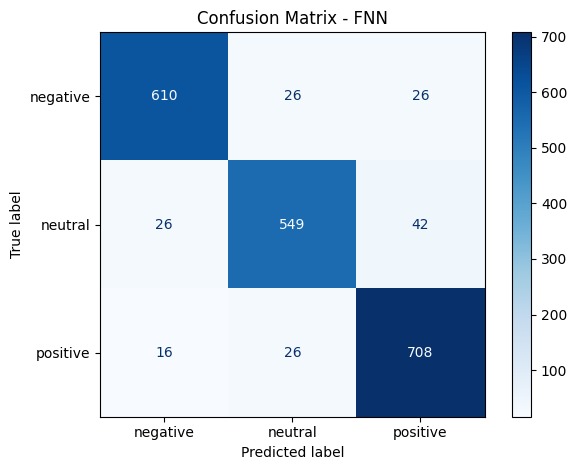

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, fnn_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - FNN")
plt.tight_layout()
plt.savefig("FNN_Confusion_Matrix.png", dpi=300)
plt.show()

In [ ]:



import time
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Reuse existing TF-IDF features and labels
Xtr = A.toarray() if hasattr(A, "toarray") else np.asarray(A)
Xte = B.toarray() if hasattr(B, "toarray") else np.asarray(B)

ytr = np.asarray(y_train)
yte = np.asarray(y_test)



experiments = {
    "Original FNN": {
        "first_layer": True,
        "dropout": True,
        "second_layer": True
    },

    "Without Dropout": {
        "first_layer": True,
        "dropout": False,
        "second_layer": True
    },

    "Without Second Dense Layer": {
        "first_layer": True,
        "dropout": True,
        "second_layer": False
    },

    "Without First Dense Layer": {
        "first_layer": False,
        "dropout": True,
        "second_layer": True
    }
}

results = []



for name, config in experiments.items():

    print("\nRunning:", name)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential()
    model.add(Input(shape=(Xtr.shape[1],)))

    if config["first_layer"]:
        model.add(Dense(128, activation="relu"))

    if config["dropout"]:
        model.add(Dropout(0.3))

    if config["second_layer"]:
        model.add(Dense(64, activation="relu"))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    model.fit(
        Xtr,
        ytr,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=0
    )

    training_time = time.time() - start_time

    # Test predictions
    predictions = model.predict(Xte, verbose=0)
    predictions = np.argmax(predictions, axis=1)

    # Evaluation
    results.append({
        "Experiment": name,

        "Accuracy (%)": round(
            accuracy_score(yte, predictions) * 100, 2
        ),

        "Precision (%)": round(
            precision_score(
                yte, predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Recall (%)": round(
            recall_score(
                yte, predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Macro F1 (%)": round(
            f1_score(
                yte, predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        ),

        "Training Time (sec)": round(training_time, 2)
    })



ablation_results = pd.DataFrame(results)

print("\n========== ABLATION STUDY RESULTS ==========")

display(ablation_results)

# Best model based on accuracy
print("\nBest configuration:")

display(
    ablation_results.loc[
        ablation_results["Accuracy (%)"].idxmax()
    ]
)


Running: Original FNN

Running: Without Dropout

Running: Without Second Dense Layer

Running: Without First Dense Layer

========== ABLATION STUDY RESULTS ==========


,Experiment,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Training Time (sec)
0,Original FNN,91.72,91.80,91.49,91.61,6.56
1,Without Dropout,91.72,91.78,91.50,91.61,8.56
2,Without Second Dense Layer,92.26,92.42,92.05,92.20,6.67
3,Without First Dense Layer,92.02,92.17,91.76,91.92,6.30



Best configuration:


,2
Experiment,Without Second Dense Layer
Accuracy (%),92.26
Precision (%),92.42
Recall (%),92.05
Macro F1 (%),92.2
Training Time (sec),6.67
